In [ ]:
import math, os
import numpy as np
import matplotlib.pyplot as plt

# uniform random number generator (LCG)
class UniformRNG:
    def __init__(self, seed=123):
        self.state = seed
        self.a = 6364136223846793005
        self.c = 1442695040888963407
        self.m = 2 ** 64

    def seed(self, seed):
        """restart the generator from a given seed (replaces random.seed)"""
        self.state = seed

    def uniform(self):
        """Uniform random number in (0, 1)"""
        self.state = (self.a * self.state + self.c) % self.m
        return ((self.state >> 11) + 0.5) / 2 ** 53   # top 53 bits, never exactly 0 or 1

    def shuffle_order(self, n):
        """Random permutation of 0..n-1 (Fisher-Yates)"""
        order = list(range(n))
        for i in range(n - 1, 0, -1):
            j = int(self.uniform() * (i + 1))
            order[i], order[j] = order[j], order[i]
        return order

rng = UniformRNG(seed=123)
os.makedirs("plots", exist_ok=True)
DATA_DIR = "TEAM_14"


In [ ]:
def random_order(n):
    return rng.shuffle_order(n)                 # Fisher-Yates driven by our own LCG

def logsumexp(a, axis=1):
    m = np.max(a, axis=axis, keepdims=True)
    return (m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))).squeeze(axis)


In [ ]:
class GMM:
    def __init__(self, K=3, reg=1e-6, max_iter=300, tol=1e-7, n_init=3):
        self.K, self.reg, self.max_iter, self.tol, self.n_init = K, reg, max_iter, tol, n_init

    def _log_gauss(self, X):                    # log N(x; mu_k, C_k), shape (N, K)
        N, d = X.shape
        out = np.empty((N, self.K))
        for k in range(self.K):
            lam, V = np.linalg.eigh(self.covs[k])              # C = V diag(lam) V^T  (eigenvalue decomposition)
            lam = np.maximum(lam, 1e-12)
            z = ((X - self.means[k]) @ V) / np.sqrt(lam)       # diag(lam)^-1/2 V^T (x - mu)
            out[:, k] = -0.5 * (d * math.log(2 * math.pi) + np.sum(np.log(lam)) + np.sum(z ** 2, axis=1))
        return out

    def _log_joint(self, X):
        return self._log_gauss(X) + np.log(self.weights)[None, :]

    def _e_step(self, X):
        lj = self._log_joint(X)
        lse = logsumexp(lj, axis=1)
        return np.exp(lj - lse[:, None]), np.sum(lse)

    def _m_step(self, X, resp):
        N, d = X.shape
        Nk = resp.sum(axis=0) + 1e-12
        self.weights = Nk / N
        self.means = (resp.T @ X) / Nk[:, None]
        covs = []
        for k in range(self.K):
            diff = X - self.means[k]
            covs.append((diff * resp[:, k][:, None]).T @ diff / Nk[k] + self.reg * np.eye(d))
        self.covs = np.array(covs)

    def _init_params(self, X):                  # random initialisation of mu_k, C_k and w_k
        N, d = X.shape
        self.means = X[rng.shuffle_order(N)[:self.K]].astype(float)        # K random data points
        C0 = np.atleast_2d(np.cov(X, rowvar=False)) + self.reg * np.eye(d)
        self.covs = np.array([C0.copy() for _ in range(self.K)])           # data covariance
        self.weights = np.ones(self.K) / self.K                            # equal weights

    def fit(self, X):
        best = None
        for _ in range(self.n_init):
            self._init_params(X)
            prev = -np.inf
            history = []                        # log-likelihood after every EM iteration
            for _ in range(self.max_iter):
                resp, ll = self._e_step(X)
                history.append(ll)
                self._m_step(X, resp)
                if abs(ll - prev) < self.tol * abs(ll):
                    break
                prev = ll
            _, ll = self._e_step(X)
            history.append(ll)
            if best is None or ll > best[0]:
                best = (ll, self.weights.copy(), self.means.copy(), self.covs.copy(), history)
        _, self.weights, self.means, self.covs, self.ll_history = best
        return self

    def score_samples(self, X):                 # log p(x)
        return logsumexp(self._log_joint(X), axis=1)

    def responsibilities(self, X):
        lj = self._log_joint(X)
        return np.exp(lj - logsumexp(lj, axis=1)[:, None])

In [ ]:
n = 5000
weights = [0.40, 0.35, 0.25]
means = [[-3.0, 3.5], [0.0, -3.0], [3.5, 1.0]]
means_2 = [[m[0] + 8.0, m[1] + 0.5] for m in means]
class_means = [means, means_2]
covariances = [[[1.6, 0.9], [0.9, 1.2]], [[2.2, 0.0], [0.0, 0.5]], [[0.8, 0.0], [0.0, 0.8]]]
covariances_2 = [[[0.6, 0.0], [0.0, 1.8]], [[1.5, -1.0], [-1.0, 1.3]], [[1.2, 0.0], [0.0, 1.2]]]
class_covariances = [covariances, covariances_2]

def box_muller_pair():
    u1, u2 = rng.uniform(), rng.uniform()      # LCG numbers are never exactly 0 or 1
    r = math.sqrt(-2 * math.log(u1))
    return r * math.cos(2 * math.pi * u2), r * math.sin(2 * math.pi * u2)

def eigen_factor(C):
    # eigenvalue decomposition C = V diag(lambda) V^T ;  A = V sqrt(diag(lambda))  gives  A A^T = C
    lam, V = np.linalg.eigh(np.asarray(C, dtype=float))
    return V * np.sqrt(lam)[None, :]

def generate_gmm(n, weights, means, covariances):
    factors = [eigen_factor(C) for C in covariances]
    pts = []
    for _ in range(n):
        u = rng.uniform()
        k = 0 if u < weights[0] else (1 if u < weights[0] + weights[1] else 2)
        z1, z2 = box_muller_pair()
        pts.append(np.asarray(means[k]) + factors[k] @ np.array([z1, z2]))   # x = mu + V sqrt(lambda) z
    return np.array(pts)

class_samples = [generate_gmm(n, weights, class_means[c], class_covariances[c]) for c in range(2)]
train_sets, test_sets = [], []
for s in class_samples:
    sh = s[random_order(n)]
    train_sets.append(sh[:int(0.8 * n)]); test_sets.append(sh[int(0.8 * n):])
print("train:", [s.shape for s in train_sets], " test:", [s.shape for s in test_sets])

train: [(4000, 2), (4000, 2)]  test: [(1000, 2), (1000, 2)]


In [ ]:
gmm2d = [GMM(K=3, reg=1e-6, n_init=5).fit(train_sets[c]) for c in range(2)]
np.set_printoptions(precision=3, suppress=True)
for c, g in enumerate(gmm2d):
    print(f"\nClass {c+1}  weights {g.weights}\nmeans\n{g.means}")

priors2d = [0.5, 0.5]                        # equal class sizes
score2d = lambda X: np.column_stack([g.score_samples(X) + math.log(p) for g, p in zip(gmm2d, priors2d)])
cm2d = np.zeros((2, 2), dtype=int)
for t, s in enumerate(test_sets):
    for p in np.argmax(score2d(s), axis=1):
        cm2d[t, p] += 1
print("\nConfusion matrix (rows = true class, columns = predicted):\n", cm2d)
print("Accuracy:", np.trace(cm2d) / cm2d.sum())


Class 1  weights [0.363 0.245 0.391]
means
[[ 0.015 -2.989]
 [ 3.534  0.997]
 [-2.977  3.53 ]]

Class 2  weights [0.254 0.342 0.404]
means
[[11.438  1.526]
 [ 7.983 -2.482]
 [ 5.011  3.984]]

Confusion matrix (rows = true class, columns = predicted):
 [[986  14]
 [ 24 976]]
Accuracy: 0.981


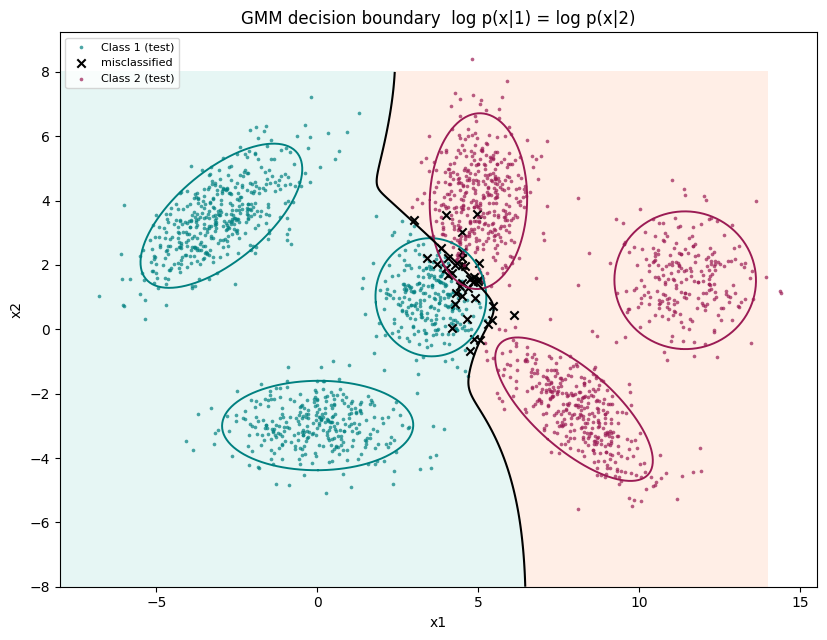

In [ ]:
def draw_ellipse(ax, mean, cov, color, n_std=2.0):
    w, V = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, 200)
    pts = (V @ (np.sqrt(w)[:, None] * np.vstack([np.cos(t), np.sin(t)]) * n_std)).T + mean
    ax.plot(pts[:, 0], pts[:, 1], color=color, lw=1.4)

col2 = ["#008080", "#9B1B54"]
xg, yg = np.meshgrid(np.linspace(-8, 14, 400), np.linspace(-8, 8, 300))
sc = score2d(np.column_stack([xg.ravel(), yg.ravel()]))
llr = (sc[:, 0] - sc[:, 1]).reshape(xg.shape)
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.contourf(xg, yg, llr > 0, levels=[-0.5, 0.5, 1.5], colors=["#FFE3D6", "#D6F0EE"], alpha=0.6)
for c, s in enumerate(test_sets):
    bad = s[np.argmax(score2d(s), axis=1) != c]
    ax.scatter(s[:, 0], s[:, 1], s=7, alpha=0.7, linewidths=0, color=col2[c], label=f"Class {c+1} (test)")
    ax.scatter(bad[:, 0], bad[:, 1], marker="x", s=36, color="k", label="misclassified" if c == 0 else None)
    for k in range(3):
        draw_ellipse(ax, gmm2d[c].means[k], gmm2d[c].covs[k], col2[c])
ax.contour(xg, yg, llr, levels=[0], colors="k", linewidths=1.5)
ax.set_aspect("equal"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("GMM decision boundary  log p(x|1) = log p(x|2)")
plt.tight_layout(); plt.savefig("plots/p1_gmm_boundary.png", dpi=200); plt.show()

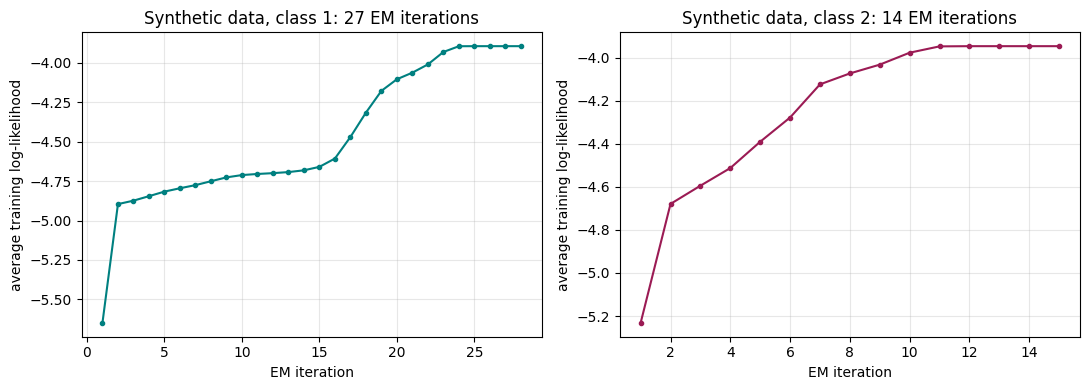

class 1: average log-likelihood -5.6485 -> -3.8953  (27 iterations)
class 2: average log-likelihood -5.2319 -> -3.9468  (14 iterations)


In [ ]:
# convergence of the average training log-likelihood during EM  (synthetic 2-D data)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, g in enumerate(gmm2d):
    h = np.array(g.ll_history) / len(train_sets[c])          # (1/N) sum_n log p(x_n)
    ax[c].plot(np.arange(1, len(h) + 1), h, "-o", ms=3, color=col2[c])
    ax[c].set_title(f"Synthetic data, class {c+1}: {len(h)-1} EM iterations")
    ax[c].set_xlabel("EM iteration"); ax[c].set_ylabel("average training log-likelihood")
    ax[c].grid(alpha=.3)
plt.tight_layout(); plt.savefig("plots/p1_convergence.png", dpi=200); plt.show()
for c, g in enumerate(gmm2d):
    h = np.array(g.ll_history) / len(train_sets[c])
    print(f"class {c+1}: average log-likelihood {h[0]:.4f} -> {h[-1]:.4f}  ({len(h)-1} iterations)")


In [ ]:
digits = [0, 1, 7]
def load_split(split):
    X, y = [], []
    for ci, d in enumerate(digits):
        folder = os.path.join(DATA_DIR, split, str(d))
        for f in sorted(os.listdir(folder)):
            X.append(plt.imread(os.path.join(folder, f)).astype(np.float64).ravel()); y.append(ci)
    return np.array(X), np.array(y)

Xtr, ytr = load_split("train"); Xdv, ydv = load_split("dev"); Xte, yte = load_split("test")
print("train", Xtr.shape, np.bincount(ytr), " dev", Xdv.shape, " test", Xte.shape, np.bincount(yte))
priors = np.bincount(ytr) / len(ytr)

pca_mu = Xtr.mean(axis=0)
w, V = np.linalg.eigh(np.cov(Xtr - pca_mu, rowvar=False))
V = V[:, np.argsort(w)[::-1]]
D = 40
P = V[:, :D]
Ftr, Fdv, Fte = [(X - pca_mu) @ P for X in (Xtr, Xdv, Xte)]

train (15101, 784) [4735 5383 4983]  dev (3829, 784)  test (3143, 784) [ 980 1135 1028]


In [ ]:
for K in [1, 2, 3, 4]:
    rng.seed(1)
    ms = [GMM(K=K, reg=1e-4, n_init=2, max_iter=80, tol=1e-5).fit(Ftr[ytr == c]) for c in range(3)]
    s = np.column_stack([g.score_samples(Fdv) + math.log(p) for g, p in zip(ms, priors)])
    print(f"K = {K}: dev accuracy {100*np.mean(np.argmax(s, axis=1) == ydv):.2f} %")

K = 1: dev accuracy 98.98 %
K = 2: dev accuracy 99.53 %
K = 3: dev accuracy 99.45 %
K = 4: dev accuracy 99.43 %


In [ ]:
K = 3
rng.seed(7)
models = [GMM(K=K, reg=1e-4, n_init=5).fit(Ftr[ytr == c]) for c in range(3)]
for c, g in enumerate(models):
    print(f"digit {digits[c]}: component weights {g.weights.round(3)}")

digit 0: component weights [0.337 0.399 0.264]
digit 1: component weights [0.397 0.466 0.137]
digit 7: component weights [0.353 0.331 0.316]


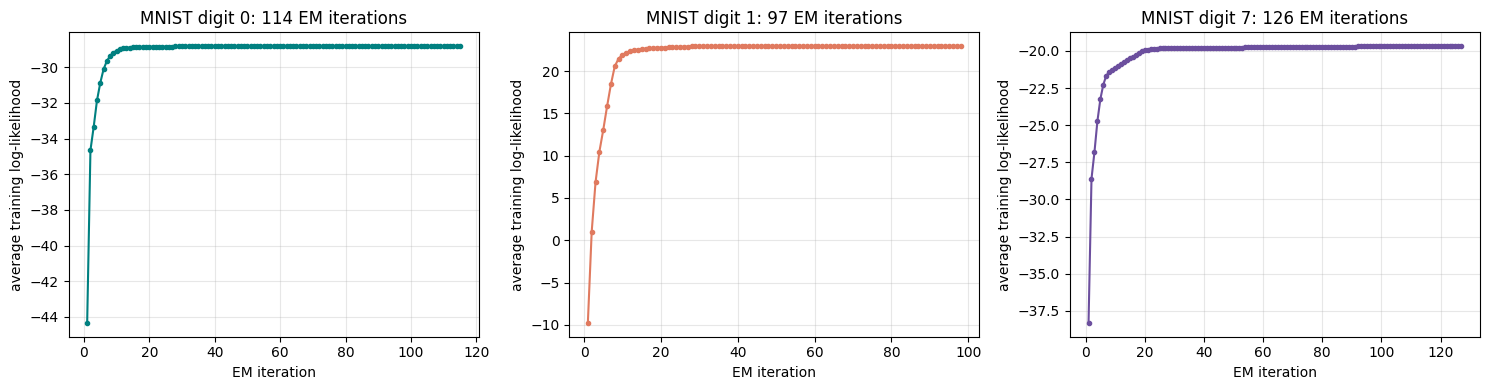

digit 0: average log-likelihood -44.334 -> -28.824  (114 iterations)
digit 1: average log-likelihood -9.775 -> 22.956  (97 iterations)
digit 7: average log-likelihood -38.314 -> -19.682  (126 iterations)


In [ ]:
# convergence of the average training log-likelihood during EM  (MNIST digits, 40-D PCA features)
mc = ["#008080", "#E07A5F", "#6C4F9E"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for c, g in enumerate(models):
    h = np.array(g.ll_history) / np.sum(ytr == c)            # (1/N) sum_n log p(x_n)
    ax[c].plot(np.arange(1, len(h) + 1), h, "-o", ms=3, color=mc[c])
    ax[c].set_title(f"MNIST digit {digits[c]}: {len(h)-1} EM iterations")
    ax[c].set_xlabel("EM iteration"); ax[c].set_ylabel("average training log-likelihood")
    ax[c].grid(alpha=.3)
plt.tight_layout(); plt.savefig("plots/p4_convergence.png", dpi=200); plt.show()
for c, g in enumerate(models):
    h = np.array(g.ll_history) / np.sum(ytr == c)
    print(f"digit {digits[c]}: average log-likelihood {h[0]:.3f} -> {h[-1]:.3f}  ({len(h)-1} iterations)")


In [ ]:
def class_scores(F):                              # log p(x|c) + log P(c)
    return np.column_stack([g.score_samples(F) + math.log(p) for g, p in zip(models, priors)])

S = class_scores(Fte)
pred = np.argmax(S, axis=1)
cm = np.zeros((3, 3), dtype=int)
for t, p in zip(yte, pred):
    cm[t, p] += 1
print("Test confusion matrix (rows = true digit, columns = predicted digit)")
print("        pred " + "  ".join(f"{d:>5d}" for d in digits))
for i, d in enumerate(digits):
    print(f"true {d}     " + "  ".join(f"{v:5d}" for v in cm[i]))
print(f"\nTest accuracy: {100*np.trace(cm)/cm.sum():.2f} %  ({np.trace(cm)} / {cm.sum()})")
for i, d in enumerate(digits):
    print(f"digit {d}: {100*cm[i,i]/cm[i].sum():.2f} % correct")

Test confusion matrix (rows = true digit, columns = predicted digit)
        pred     0      1      7
true 0       979      0      1
true 1         0   1134      1
true 7         1     10   1017

Test accuracy: 99.59 %  (3130 / 3143)
digit 0: 99.90 % correct
digit 1: 99.91 % correct
digit 7: 98.93 % correct


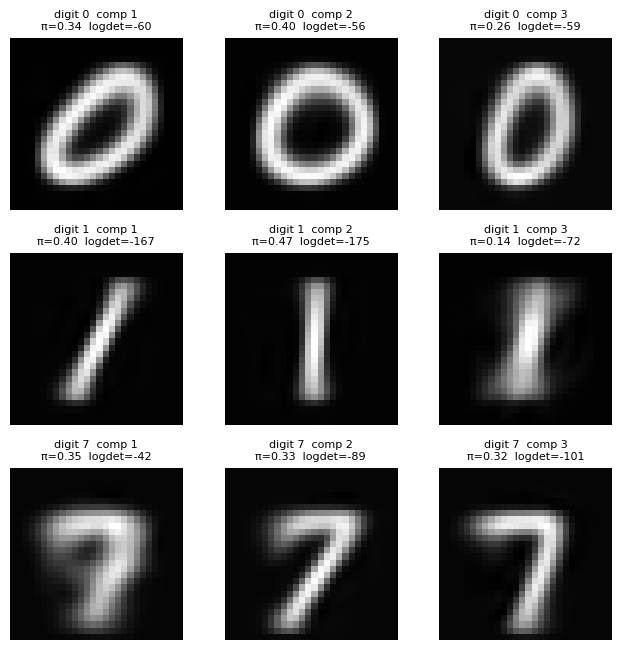

In [ ]:
fig, ax = plt.subplots(3, K, figsize=(2.2 * K, 6.6))
for c, g in enumerate(models):
    for k in range(K):
        ax[c, k].imshow((g.means[k] @ P.T + pca_mu).reshape(28, 28), cmap="gray"); ax[c, k].axis("off")
        ax[c, k].set_title(f"digit {digits[c]}  comp {k+1}\nπ={g.weights[k]:.2f}  logdet={np.linalg.slogdet(g.covs[k])[1]:.0f}", fontsize=8)
plt.tight_layout(); plt.savefig("plots/p4_components.png", dpi=200); plt.show()

13 misclassified test images
image 629: true 0 -> predicted 7   scores (1/4/6) = [ -51.5 -249.2  -48.1]   score gap = 3.4
image 1328: true 1 -> predicted 7   scores (1/4/6) = [-186.6 -127.8 -101.9]   score gap = 25.9
image 2241: true 7 -> predicted 1   scores (1/4/6) = [-112.4  -50.8  -64.9]   score gap = 14.1
image 2244: true 7 -> predicted 1   scores (1/4/6) = [-160.4  -27.2  -50.2]   score gap = 23.0
image 2265: true 7 -> predicted 1   scores (1/4/6) = [-126.8  -21.2  -37.3]   score gap = 16.1
image 2269: true 7 -> predicted 1   scores (1/4/6) = [-148.9  -39.   -40.5]   score gap = 1.5
image 2389: true 7 -> predicted 1   scores (1/4/6) = [-117.2  -66.3  -79. ]   score gap = 12.7
image 2513: true 7 -> predicted 0   scores (1/4/6) = [-65.5 -67.6 -88. ]   score gap = 22.5
image 2515: true 7 -> predicted 1   scores (1/4/6) = [-152.6  -52.4  -62.5]   score gap = 10.0
image 2523: true 7 -> predicted 1   scores (1/4/6) = [-173.3  -35.1  -46.6]   score gap = 11.5
image 2615: true 7 -> predi

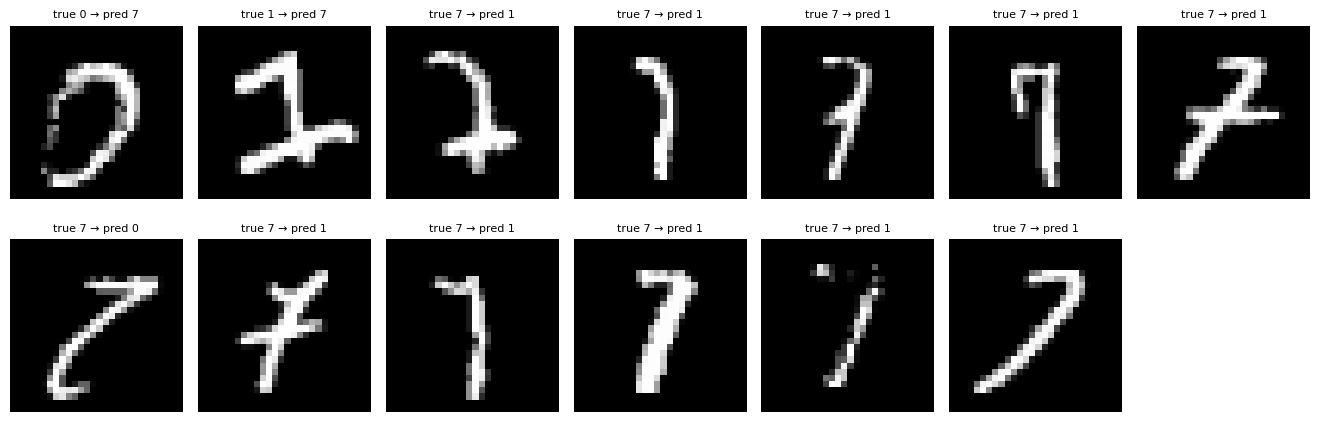

In [ ]:
# the misclassified test images
wrong = np.where(pred != yte)[0]
print(f"{len(wrong)} misclassified test images")
for i in wrong:
    print(f"image {i}: true {digits[yte[i]]} -> predicted {digits[pred[i]]}   scores (1/4/6) = {S[i].round(1)}   score gap = {S[i, pred[i]] - S[i, yte[i]]:.1f}")
cols = 7
rows = int(np.ceil(len(wrong) / cols))
fig, ax = plt.subplots(rows, cols, figsize=(1.9 * cols, 2.3 * rows))
for a in ax.ravel():
    a.axis("off")
for a, i in zip(ax.ravel(), wrong):
    a.imshow(Xte[i].reshape(28, 28), cmap="gray")
    a.set_title(f"true {digits[yte[i]]} → pred {digits[pred[i]]}", fontsize=8)
plt.tight_layout(); plt.savefig("plots/p4_misclassified.png", dpi=200); plt.show()

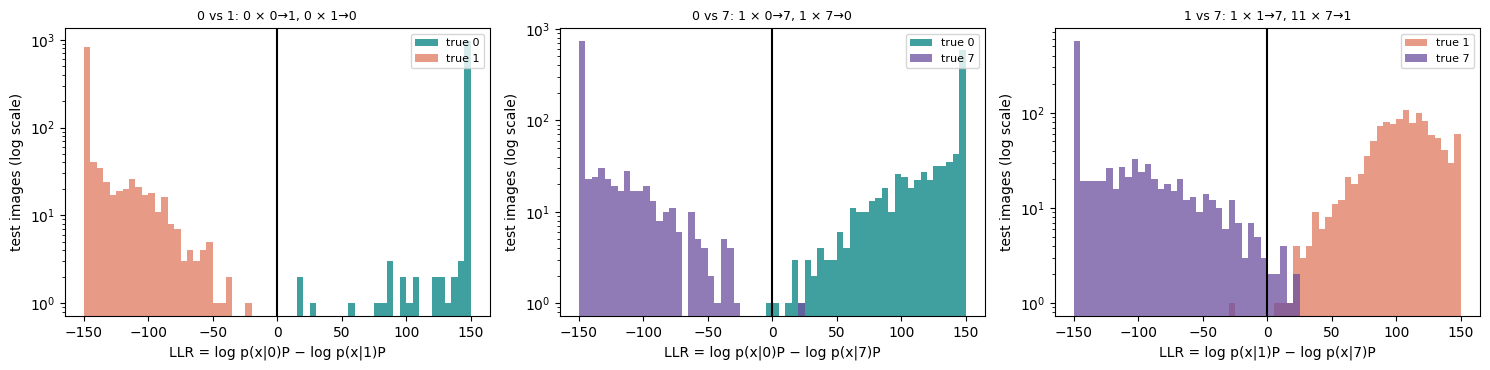

In [ ]:
# boundary between each pair of digits
pairs = [(0, 1), (0, 2), (1, 2)]
pc = ["#008080", "#E07A5F", "#6C4F9E"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a_, (a, b) in zip(ax, pairs):
    llr_ab = S[:, a] - S[:, b]
    bins = np.linspace(-150, 150, 61)
    a_.hist(np.clip(llr_ab[yte == a], -150, 150), bins=bins, alpha=.75, color=pc[a], label=f"true {digits[a]}")
    a_.hist(np.clip(llr_ab[yte == b], -150, 150), bins=bins, alpha=.75, color=pc[b], label=f"true {digits[b]}")
    a_.axvline(0, color="k", lw=1.5); a_.set_yscale("log")
    n_ab = int(np.sum((yte == a) & (llr_ab < 0))); n_ba = int(np.sum((yte == b) & (llr_ab > 0)))
    a_.set_title(f"{digits[a]} vs {digits[b]}: {n_ab} × {digits[a]}→{digits[b]}, {n_ba} × {digits[b]}→{digits[a]}", fontsize=9)
    a_.set_xlabel(f"LLR = log p(x|{digits[a]})P − log p(x|{digits[b]})P"); a_.set_ylabel("test images (log scale)"); a_.legend(fontsize=8)
plt.tight_layout(); plt.savefig("plots/p4_llr_pairs.png", dpi=200); plt.show()

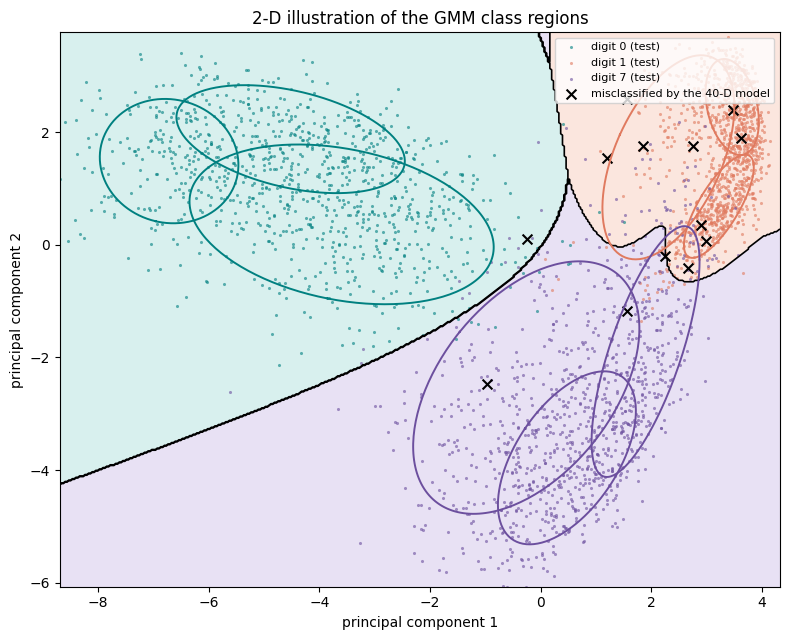

In [ ]:
rng.seed(11)
m2 = [GMM(K=3, reg=1e-4, n_init=5).fit(Ftr[ytr == c][:, :2]) for c in range(3)]
sc2 = lambda F: np.column_stack([g.score_samples(F) + math.log(p) for g, p in zip(m2, priors)])
F2 = Fte[:, :2]
lo, hi = np.percentile(F2, 0.3, axis=0) - 0.3, np.percentile(F2, 99.7, axis=0) + 0.3
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 400), np.linspace(lo[1], hi[1], 400))
region = np.argmax(sc2(np.column_stack([gx.ravel(), gy.ravel()])), axis=1).reshape(gx.shape)
dc = ["#008080", "#E07A5F", "#6C4F9E"]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.contourf(gx, gy, region, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#CFEDEA", "#FBE0D6", "#E3DAF2"], alpha=.8)
ax.contour(gx, gy, region, levels=[0.5, 1.5], colors="k", linewidths=1.2)
for c in range(3):
    ax.scatter(F2[yte == c, 0], F2[yte == c, 1], s=5, alpha=.6, linewidths=0, color=dc[c], label=f"digit {digits[c]} (test)")
    for k in range(3):
        draw_ellipse(ax, m2[c].means[k], m2[c].covs[k], dc[c], n_std=1.5)
ax.scatter(F2[wrong, 0], F2[wrong, 1], marker="x", s=50, color="k", label="misclassified by the 40-D model")
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.legend(fontsize=8, loc="upper right")
ax.set_xlabel("principal component 1"); ax.set_ylabel("principal component 2")
ax.set_title("2-D illustration of the GMM class regions"); plt.tight_layout()
plt.savefig("plots/p4_boundary_2d.png", dpi=200); plt.show()